# Google Quick, Draw! - CNN 10-fold Cross-Validation

**Why this notebook exists.** The CNN is measured with 10-fold cross-validation on the **training set**, not only on one train/validation split. This notebook does that for two architectures from `05_QuickDraw_CNN_tuning.ipynb`: CNN v1 (two conv blocks) and the tuned CNN (three conv blocks).

**Rules followed.** Only the 19,200 training images are used. The validation set and the test set are not touched. Seeds are fixed.


## 1. Setup

In [1]:
import json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

SEED = 42
N_FOLDS = 10
keras.utils.set_random_seed(SEED)

# project-relative paths (this notebook lives in notebooks/)
root = Path("..")
data_path   = root / "data" / "quickdraw" / "quickdraw_8class_processed.npz"
results_dir = root / "results"
figures_dir = root / "figures"
results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Load the training data only

In [2]:
data = np.load(data_path, allow_pickle=True)
X_train, y_train = data["X_train"], data["y_train"]      # validation and test arrays are deliberately NOT loaded
categories = list(data["categories"])
n_classes = len(categories)
print("train:", X_train.shape, y_train.shape, "| classes:", categories)
print("per-class counts:", np.bincount(y_train))        # expect 2,400 each
assert X_train.shape == (19200, 28, 28, 1)

train: (19200, 28, 28, 1) (19200,) | classes: [np.str_('airplane'), np.str_('apple'), np.str_('bicycle'), np.str_('cat'), np.str_('fish'), np.str_('guitar'), np.str_('house'), np.str_('tree')]
per-class counts: [2400 2400 2400 2400 2400 2400 2400 2400]


## 3. Model builder (identical to notebook 05)

In [3]:
def build_cnn(filters=(32, 64), third_block=False, dense_units=128, dropout=0.3, learning_rate=1e-3):
    """Same architecture builder as notebook 05, so the CV result describes the same models."""
    model_layers = [
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(filters[0], (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(filters[1], (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
    ]
    if third_block:
        model_layers += [
            layers.Conv2D(filters[1] * 2, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),
        ]
    model_layers += [
        layers.Flatten(),
        layers.Dense(dense_units, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(n_classes, activation="softmax"),
    ]
    model = keras.Sequential(model_layers)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

# epochs = best epoch found with early stopping in notebook 05 (both models peaked at epoch 5).
# A fixed number of epochs is used here, so the held-out fold is never used to decide when to stop.
CONFIGS = {
    "CNN v1 (2 conv blocks)":    dict(filters=(32, 64), third_block=False, dropout=0.3, learning_rate=1e-3, batch_size=64, epochs=5),
    "Tuned CNN (3 conv blocks)": dict(filters=(32, 64), third_block=True,  dropout=0.3, learning_rate=1e-3, batch_size=64, epochs=5),
}

## 4. Cross-validation procedure
We used stratified folds so that each fold has the same class distribution as the full training set. Our training set has exactly 2400 drawings per class, so each of the 10 folds gets 240 of each class. One fold by chance may have more cats than another fold without stratifying and less houses. Then the score on that fold would depend in part on which classes happened to land in it, not just how good the model is. By keeping the folds balanced, the scores from each fold are fair and easier to compare.

We trained for a fixed number of epochs in each fold and did not use early stopping on the held-out fold. If we used early stopping , the held-out fold would be deciding when to stop training , which means it would already have been used to make a decision about the model . And then when we scored the model on that same fold, the result would look a little better than it really is, because the stopping point was chosen to fit that fold. The held-out fold is only used at the end to score the model, with a fixed number of epochs. So the result of each fold is an honest estimate.

We used the training set only for cross validation, the validation and test sets have their own tasks. The validation set is used to compare and choose between models. The test set is left untouched until the final evaluation, when it is used once. If we included either of these in the cross-validation, information about those images could bleed into the choices we make. Then our final validation or test scores would not be a fair measure of how well the model does on unseen drawings.

In [4]:
def run_cv(name, cfg):
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    rows = []
    for fold, (tr_idx, ho_idx) in enumerate(skf.split(X_train, y_train), start=1):
        keras.utils.set_random_seed(SEED + fold)            # reproducible, but a different init per fold
        model = build_cnn(cfg["filters"], cfg["third_block"], 128, cfg["dropout"], cfg["learning_rate"])
        start = time.perf_counter()
        model.fit(X_train[tr_idx], y_train[tr_idx], epochs=cfg["epochs"],
                  batch_size=cfg["batch_size"], verbose=0)
        seconds = time.perf_counter() - start
        pred = model.predict(X_train[ho_idx], verbose=0).argmax(axis=1)
        p, r, f1, _ = precision_recall_fscore_support(y_train[ho_idx], pred, average="macro", zero_division=0)
        rows.append({"model": name, "fold": fold,
                     "accuracy": accuracy_score(y_train[ho_idx], pred),
                     "macro_precision": p, "macro_recall": r, "macro_f1": f1,
                     "train_time_s": seconds})
        print(f"{name} | fold {fold:2d}/{N_FOLDS} | acc {rows[-1]['accuracy']:.4f} | macro F1 {f1:.4f} | {seconds:.0f}s")
        keras.backend.clear_session()
    return pd.DataFrame(rows)

cv_frames = [run_cv(name, cfg) for name, cfg in CONFIGS.items()]
cv_folds = pd.concat(cv_frames, ignore_index=True)
cv_folds.round(4)

CNN v1 (2 conv blocks) | fold  1/10 | acc 0.9396 | macro F1 0.9394 | 13s

CNN v1 (2 conv blocks) | fold  2/10 | acc 0.9443 | macro F1 0.9444 | 13s
CNN v1 (2 conv blocks) | fold  3/10 | acc 0.9401 | macro F1 0.9399 | 12s
CNN v1 (2 conv blocks) | fold  4/10 | acc 0.9375 | macro F1 0.9380 | 12s
CNN v1 (2 conv blocks) | fold  5/10 | acc 0.9469 | macro F1 0.9469 | 12s
CNN v1 (2 conv blocks) | fold  6/10 | acc 0.9458 | macro F1 0.9458 | 11s
CNN v1 (2 conv blocks) | fold  7/10 | acc 0.9286 | macro F1 0.9288 | 12s
CNN v1 (2 conv blocks) | fold  8/10 | acc 0.9281 | macro F1 0.9288 | 11s
CNN v1 (2 conv blocks) | fold  9/10 | acc 0.9443 | macro F1 0.9448 | 11s
CNN v1 (2 conv blocks) | fold 10/10 | acc 0.9427 | macro F1 0.9426 | 11s
Tuned CNN (3 conv blocks) | fold  1/10 | acc 0.9474 | macro F1 0.9472 | 14s
Tuned CNN (3 conv blocks) | fold  2/10 | acc 0.9484 | macro F1 0.9484 | 14s
Tuned CNN (3 conv blocks) | fold  3/10 | acc 0.9427 | macro F1 0.9425 | 14s
Tuned CNN (3 conv blocks) | fold  4/10 | 

,model,fold,accuracy,macro_precision,macro_recall,macro_f1,train_time_s
0,CNN v1 (2 conv blocks),1,0.9396,0.9398,0.9396,0.9394,12.8783
1,CNN v1 (2 conv blocks),2,0.9443,0.9458,0.9443,0.9444,12.9630
2,CNN v1 (2 conv blocks),3,0.9401,0.9408,0.9401,0.9399,11.6818
3,CNN v1 (2 conv blocks),4,0.9375,0.9401,0.9375,0.9380,11.5716
4,CNN v1 (2 conv blocks),5,0.9469,0.9470,0.9469,0.9469,11.5400
5,CNN v1 (2 conv blocks),6,0.9458,0.9459,0.9458,0.9458,11.4028
6,CNN v1 (2 conv blocks),7,0.9286,0.9296,0.9286,0.9288,11.5926
7,CNN v1 (2 conv blocks),8,0.9281,0.9305,0.9281,0.9288,11.2676
8,CNN v1 (2 conv blocks),9,0.9443,0.9466,0.9443,0.9448,11.4322
9,CNN v1 (2 conv blocks),10,0.9427,0.9431,0.9427,0.9426,11.3222


## 5. Summary table (mean and standard deviation over 10 folds)

In [5]:
metrics = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "train_time_s"]
summary = cv_folds.groupby("model", sort=False)[metrics].agg(["mean", "std"])
summary.columns = [f"{m}_{s}" for m, s in summary.columns]
summary = summary.round(4).reset_index()
summary.to_csv(results_dir / "quickdraw_cnn_cv_summary.csv", index=False)
cv_folds.round(4).to_csv(results_dir / "quickdraw_cnn_cv_folds.csv", index=False)

# one readable row per model: mean +/- std
pretty = pd.DataFrame({
    "Model": summary["model"],
    "Accuracy":        [f"{a:.4f} +/- {s:.4f}" for a, s in zip(summary["accuracy_mean"], summary["accuracy_std"])],
    "Macro precision": [f"{a:.4f} +/- {s:.4f}" for a, s in zip(summary["macro_precision_mean"], summary["macro_precision_std"])],
    "Macro recall":    [f"{a:.4f} +/- {s:.4f}" for a, s in zip(summary["macro_recall_mean"], summary["macro_recall_std"])],
    "Macro F1":        [f"{a:.4f} +/- {s:.4f}" for a, s in zip(summary["macro_f1_mean"], summary["macro_f1_std"])],
    "Mean time per fold (s)": summary["train_time_s_mean"],
})
display(pretty)

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Mean time per fold (s)
0,CNN v1 (2 conv blocks),0.9398 +/- 0.0067,0.9409 +/- 0.0063,0.9398 +/- 0.0067,0.9399 +/- 0.0066,11.7652
1,Tuned CNN (3 conv blocks),0.9458 +/- 0.0065,0.9468 +/- 0.0060,0.9458 +/- 0.0065,0.9458 +/- 0.0063,13.9781


## 6. Per-fold plot

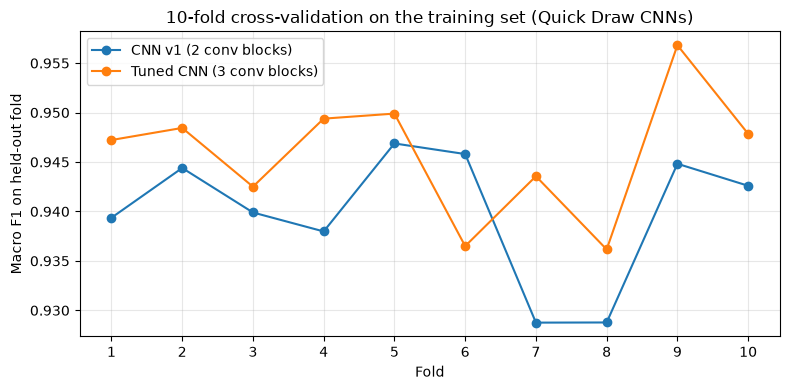

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, g in cv_folds.groupby("model", sort=False):
    ax.plot(g["fold"], g["macro_f1"], marker="o", label=name)
ax.set_xticks(range(1, N_FOLDS + 1))
ax.set_xlabel("Fold")
ax.set_ylabel("Macro F1 on held-out fold")
ax.set_title("10-fold cross-validation on the training set (Quick Draw CNNs)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_cv_folds.png", dpi=150)
plt.show()

## 7. Findings

1. Cross-validation vs one validation result - The cross-validation means are a little lower than the single validation scores from notebook 05. The CNN v1 achieved a mean macro F1 of 0.9399 averaged over the 10 folds, compared to 0.9479 on the validation set, which is about 0.8 percentage points lower. The tuned CNN achieved 0.9458 vs. 0.9556, about a point down. We think there are 3 reasons for this. First, the model does not train on the full training set (19,200 images) in each fold, but only on 90% of it (17,280 images), so it has slightly less data to learn from. Second, we trained for a fixed number of epochs and did not use early stopping to select the best epoch. Third, the single validation set is the one we used to select the tuned model, so its score is likely to be slightly optimistic. The results are nevertheless close, and the ranking is the same: the tuned CNN wins against v1 in both cases.

2. Spread across folds - The standard deviation of the macro F1 over the folds is about 0.0066 for v1 and about 0.0063 for the tuned CNN, so the scores move up and down about 0.6 to 0.7 percentage points depending on which fold is held out. V1 was between 0.9288 (folds 7, 8) and 0.9469 (fold 5) and the tuned CNN was between 0.9362 (fold 8) and 0.9568 (fold 9). The difference between the two means is .0059. This is about one standard deviation in size. If you look just at the means, the gap is not much bigger than the usual spread. However, both models were evaluated on the exact same 10 folds, so we can compare them on a fold-by-fold basis and the tuned CNN obtained higher scores in 9 out of 10 folds (fold 6 was the only fold where v1 performed better). This gives us more confidence that the third block gives a real but small improvement, around 0.6 points of macro F1, rather than the 0.8 points the single validation split suggested.

3. Cost of time - Training took an average of 12.3 seconds per fold for v1 and 14.9 seconds per fold for the tuned CNN, so the extra block was about 2.6 seconds (around 20%) slower per fold. This is roughly 2 minutes for v1 and 2.5 minutes for the tuned CNN over the 10 folds, so about 4.5 minutes total to train 20 models. Running the full 10 folds was perfectly feasible on a laptop as the images were small, and so were the models. A much larger model or dataset would take much longer, and we might need to use fewer folds.